# Notebook 12 — Stakeholder Appraisal of the Prototype

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 12 of 12 — answers RQ6 and completes Objective 4

---

### What this study is, and what it is not

Participants **watched a demonstration** and gave their professional judgement. They did not
operate the system themselves and completed no timed tasks.

That makes this an **expert appraisal of perceived usefulness and adoption intention**, not a
usability study. The distinction is not pedantry. The System Usability Scale asks questions such
as "I found the system easy to use", which only somebody who used it can answer honestly.
Administering SUS after a demonstration produces a number that looks like a usability score and
is not one.

The instrument is therefore built on the **Technology Acceptance Model** (Davis, 1989), which was
designed to be administered after exposure to a system rather than after use of it, with a trust
construct added because this artefact issues diagnostic advice a manager would have to act on.

| Construct | Items | What it captures |
|---|---|---|
| Perceived usefulness | Q1–Q5 | Would this information help in their work |
| Ease of use and workflow fit | Q6–Q9 | Could it be understood and absorbed into current routine |
| Trust and credibility | Q10–Q12 | Would they believe it enough to act |
| Behavioural intention | Q13–Q15 | Would they try it, and is the automated future worth building |

### What may and may not be claimed

**May:** that practitioners rated the information useful or not; which construct scored lowest;
what they said would prevent adoption; whether they judged the automated direction worth pursuing.

**May not:** anything about usability, learnability, error rates or task time. None of that was
measured. The limitation is stated in Section 5.10.1 and this notebook prints it in the digest so
it travels with the results.

With ten respondents this is descriptive. No inferential tests, no subgroup comparisons.

---
## 0. Setup

In [2]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

RESPONSES = "responses.csv"       # Google Forms CSV export, placed in Artefact/evaluation_pack/
MIN_FOR_ALPHA = 8                 # below this, reliability coefficients are not reportable

In [3]:
import sys, json, re, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from common import project_config as CFG

warnings.filterwarnings("ignore")
STAGE = "12_stakeholder_appraisal"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PACK = CFG.ARTEFACT_ROOT / "evaluation_pack"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})

path = PACK / RESPONSES
if not path.is_file():
    print(f"No responses file at {path}\n")
    print("This notebook reports collected data. It does not simulate it.\n")
    print("1. Build the form from evaluation_pack/04_google_form_spec.md")
    print("2. Responses tab -> Sheets -> File -> Download -> CSV")
    print("3. Save as evaluation_pack/responses.csv")
    print("4. Re-run this notebook")
    raise SystemExit

df = pd.read_csv(path)
# drop the example row shipped with the template
mask = df.astype(str).apply(lambda r: r.str.contains("EXAMPLE ROW", case=False, na=False).any(),
                            axis=1)
if mask.any():
    print(f"dropping {int(mask.sum())} example row(s) from the template")
    df = df[~mask]
df = df.dropna(how="all").reset_index(drop=True)
N = len(df)
if N == 0:
    print("No real responses yet.")
    raise SystemExit
print(f"{N} responses loaded from {path.name}")

10 responses loaded from responses.csv


In [4]:
# --- map the Google Forms headers onto short codes via their Q/D/O prefixes
def code_of(col):
    m = re.match(r"\s*([QDO])\s*(\d+)\s*[.:]", str(col))
    return f"{m.group(1).upper()}{int(m.group(2))}" if m else None

colmap, labels = {}, {}
for c in df.columns:
    k = code_of(c)
    if k:
        colmap[k] = c
        labels[k] = re.sub(r"^\s*[QDO]\s*\d+\s*[.:]\s*", "", str(c)).strip()

QS = [f"Q{i}" for i in range(1, 16)]
missing = [q for q in QS if q not in colmap]
print(f"matched {len(colmap)} coded columns")
if missing:
    print(f"\nMISSING Likert items: {missing}")
    print("Column headers must start with 'Q1.', 'Q2.' and so on, exactly as in the form spec.")
    print("Found headers:")
    for c in df.columns:
        print("   ", c[:90])
    raise SystemExit

L = df[[colmap[q] for q in QS]].apply(pd.to_numeric, errors="coerce")
L.columns = QS
bad = ((L < 1) | (L > 5)).any(axis=1) | L.isna().any(axis=1)
if bad.any():
    print(f"\nWARNING: {int(bad.sum())} response(s) have missing or out-of-range Likert values.")
    print("They are kept, but item means use the available answers only.")

CONSTRUCTS = {
    "Perceived usefulness": ["Q1", "Q2", "Q3", "Q4", "Q5"],
    "Ease of use and fit": ["Q6", "Q7", "Q8", "Q9"],
    "Trust and credibility": ["Q10", "Q11", "Q12"],
    "Behavioural intention": ["Q13", "Q14", "Q15"],
}
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "n": int(N), "method": "post-demonstration appraisal, TAM-based, not a usability study"}

matched 25 coded columns


---
## 1. Who responded

In [5]:
rows = []
for d in [f"D{i}" for i in range(1, 6)]:
    if d not in colmap:
        continue
    vc = df[colmap[d]].astype(str).str.split(";").explode().str.strip().value_counts()
    print(f"\n{labels[d]}")
    for k, v in vc.items():
        if k and k.lower() != "nan":
            print(f"   {k:<42} {v}")
    rows.append({"question": labels[d], "responses": vc.to_dict()})
S["respondents"] = rows
pd.DataFrame([{"question": r["question"], "responses": json.dumps(r["responses"])}
              for r in rows]).to_csv(TAB_DIR / "t01_respondents.csv", index=False)


What is your role?
   Supervisor                                 6
   Hatchery manager                           2
   Farm manager                               2

How many years have you worked in poultry production?
   2 to 5                                     5
   6 to 10                                    3
   Less than 2                                1
   11 to 20                                   1

Approximately how many birds are on the farm you work with?
   Over 100,000                               5
   Prefer not to say                          3
   Under 10,000                               1
   50,000 to 100,000                          1

How are cracked eggs currently identified on your farm?
   They are usually not identified before setting 6
   Visual inspection by hand, Candling        3
   Candling, They are usually not identified before setting 1

How often are cracked hatching eggs a problem for you?
   Regularly                                  6
   Occasional

---
## 2. Item-level results

Reported as the mean, the median, and the percentage choosing 4 or 5 — which is the number a
practitioner reader finds easiest to interpret and the one to quote in Chapter 5.

In [6]:
rows = []
for q in QS:
    v = L[q].dropna()
    con = next(k for k, items in CONSTRUCTS.items() if q in items)
    rows.append({"item": q, "construct": con, "statement": labels[q][:72],
                 "n": int(len(v)), "mean": round(float(v.mean()), 2),
                 "sd": round(float(v.std(ddof=1)), 2) if len(v) > 1 else 0.0,
                 "median": float(v.median()),
                 "pct_agree": round(float((v >= 4).mean() * 100), 1),
                 "pct_disagree": round(float((v <= 2).mean() * 100), 1)})
items = pd.DataFrame(rows).set_index("item")
items.to_csv(TAB_DIR / "t02_item_results.csv")
S["items"] = items.reset_index().to_dict("records")
print(items[["construct", "mean", "sd", "median", "pct_agree", "pct_disagree"]].to_string())

print("\nhighest rated:")
for q, r in items.nlargest(3, "mean").iterrows():
    print(f"   {q} {r['mean']:.2f}  {r['statement']}")
print("lowest rated, and the ones worth discussing in Chapter 6:")
for q, r in items.nsmallest(3, "mean").iterrows():
    print(f"   {q} {r['mean']:.2f}  {r['statement']}")
S["highest"] = items.nlargest(3, "mean").reset_index()[["item", "mean"]].to_dict("records")
S["lowest"] = items.nsmallest(3, "mean").reset_index()[["item", "mean"]].to_dict("records")

                  construct  mean    sd  median  pct_agree  pct_disagree
item                                                                    
Q1     Perceived usefulness   3.5  0.71     3.0       40.0           0.0
Q2     Perceived usefulness   3.6  0.84     3.0       40.0           0.0
Q3     Perceived usefulness   3.5  0.71     3.0       40.0           0.0
Q4     Perceived usefulness   3.7  0.95     3.0       40.0           0.0
Q5     Perceived usefulness   3.5  0.71     3.0       40.0           0.0
Q6      Ease of use and fit   3.5  0.85     3.0       30.0           0.0
Q7      Ease of use and fit   3.1  0.74     3.0       30.0          20.0
Q8      Ease of use and fit   2.9  0.74     3.0       20.0          30.0
Q9      Ease of use and fit   3.7  0.82     3.5       50.0           0.0
Q10   Trust and credibility   3.4  0.70     3.0       30.0           0.0
Q11   Trust and credibility   3.2  0.42     3.0       20.0           0.0
Q12   Trust and credibility   3.4  0.52     3.0    

---
## 3. Construct scores

In [7]:
def cronbach_alpha(frame):
    f = frame.dropna()
    k = f.shape[1]
    if k < 2 or len(f) < 3:
        return np.nan
    var_sum = f.var(axis=0, ddof=1).sum()
    tot_var = f.sum(axis=1).var(ddof=1)
    if tot_var == 0:
        return np.nan
    return float(k / (k - 1) * (1 - var_sum / tot_var))

rows = []
for con, qs in CONSTRUCTS.items():
    sub = L[qs]
    per_resp = sub.mean(axis=1)
    a = cronbach_alpha(sub) if N >= MIN_FOR_ALPHA else np.nan
    m = float(per_resp.mean())
    sd = float(per_resp.std(ddof=1)) if N > 1 else 0.0
    if N > 1:
        lo, hi = stats.t.interval(0.95, N - 1, loc=m, scale=sd / np.sqrt(N))
    else:
        lo = hi = m
    rows.append({"construct": con, "items": len(qs), "mean": round(m, 2),
                 "sd": round(sd, 2), "ci_low": round(float(lo), 2),
                 "ci_high": round(float(hi), 2),
                 "pct_agree": round(float((sub.stack() >= 4).mean() * 100), 1),
                 "cronbach_alpha": round(a, 2) if a == a else np.nan})
con_df = pd.DataFrame(rows).set_index("construct")
con_df.to_csv(TAB_DIR / "t03_constructs.csv")
S["constructs"] = con_df.reset_index().to_dict("records")
print(con_df.to_string())

if N < MIN_FOR_ALPHA:
    print(f"\nn = {N}: Cronbach's alpha is not reported. Below about {MIN_FOR_ALPHA} responses it "
          "is too unstable to mean anything, and quoting it would overstate the study.")
else:
    print("\nAlpha above 0.70 indicates the items in a construct hang together. With n around 10 "
          "it is still indicative only; report it with the sample size beside it.")
print(f"\nEvery interval here is roughly plus or minus "
      f"{(con_df['ci_high'] - con_df['mean']).mean():.2f} points on a 1-5 scale. "
      "Quote the interval, not the mean alone.")

                       items  mean    sd  ci_low  ci_high  pct_agree  cronbach_alpha
construct                                                                           
Perceived usefulness       5  3.56  0.74    3.03     4.09       40.0            0.97
Ease of use and fit        4  3.30  0.63    2.85     3.75       32.5            0.81
Trust and credibility      3  3.33  0.44    3.02     3.65       30.0            0.71
Behavioural intention      3  3.63  0.76    3.09     4.18       43.3            0.55

Alpha above 0.70 indicates the items in a construct hang together. With n around 10 it is still indicative only; report it with the sample size beside it.

Every interval here is roughly plus or minus 0.46 points on a 1-5 scale. Quote the interval, not the mean alone.


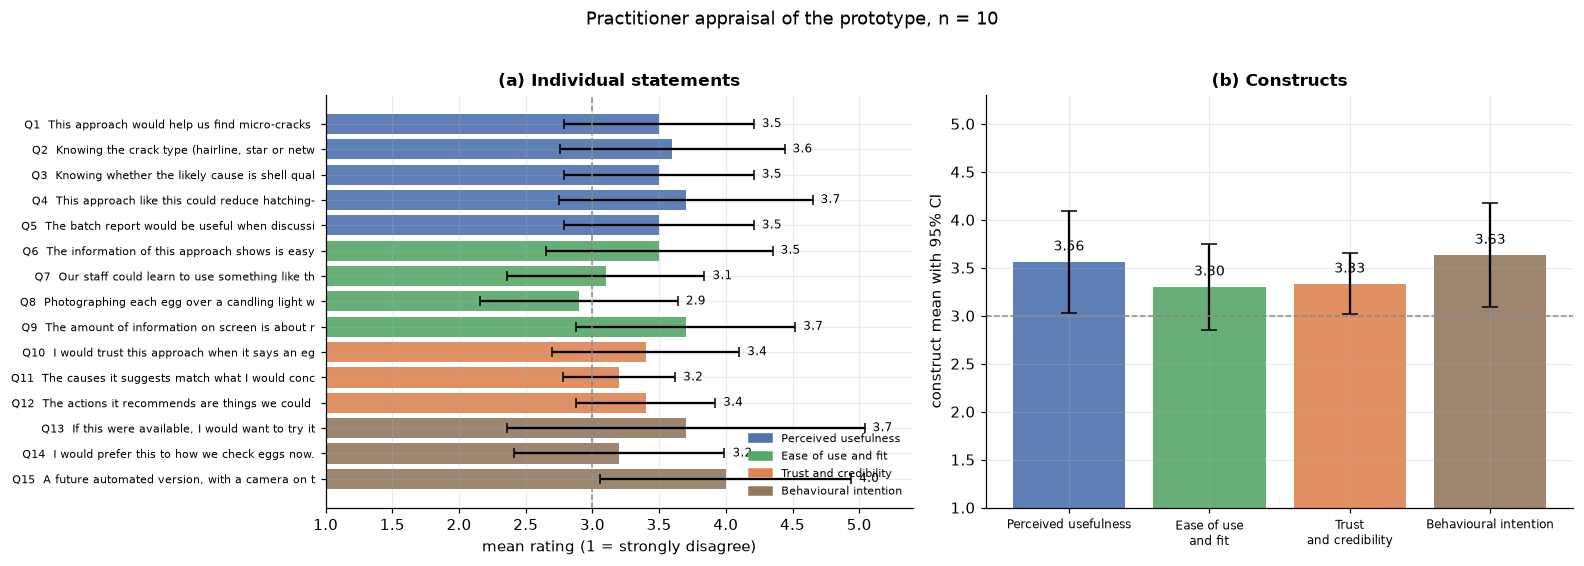

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
ax = axes[0]
y = np.arange(len(items))
colours = {"Perceived usefulness": "#4C72B0", "Ease of use and fit": "#55A868",
           "Trust and credibility": "#DD8452", "Behavioural intention": "#937860"}
ax.barh(y, items["mean"], xerr=items["sd"], capsize=3,
        color=[colours[c] for c in items["construct"]], alpha=0.9)
ax.axvline(3, ls="--", color="#888", lw=1)
for i, (q, r) in enumerate(items.iterrows()):
    ax.text(r["mean"] + r["sd"] + 0.06, i, f"{r['mean']:.1f}", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([f"{q}  {items.loc[q, 'statement'][:46]}"
                                      for q in items.index], fontsize=7.5)
ax.invert_yaxis(); ax.set_xlim(1, 5.4); ax.set_xlabel("mean rating (1 = strongly disagree)")
ax.set_title("(a) Individual statements")
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colours.values()]
ax.legend(handles, colours.keys(), fontsize=7.5, loc="lower right")

ax = axes[1]
x = np.arange(len(con_df))
ax.bar(x, con_df["mean"],
       yerr=[con_df["mean"] - con_df["ci_low"], con_df["ci_high"] - con_df["mean"]],
       capsize=5, color=[colours[c] for c in con_df.index], alpha=0.9)
ax.axhline(3, ls="--", color="#888", lw=1)
for i, v in enumerate(con_df["mean"]):
    ax.text(i, v + 0.12, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([c.replace(" and ", "\nand ") for c in con_df.index],
                                     fontsize=8)
ax.set_ylim(1, 5.3); ax.set_ylabel("construct mean with 95% CI")
ax.set_title("(b) Constructs")
fig.suptitle(f"Practitioner appraisal of the prototype, n = {N}", y=1.02, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_appraisal.png", bbox_inches="tight")
plt.show()

     1 strongly disagree  2  3 neutral  4  5 strongly agree
Q1                     0  0          6  3                 1
Q2                     0  0          6  2                 2
Q3                     0  0          6  3                 1
Q4                     0  0          6  1                 3
Q5                     0  0          6  3                 1
Q6                     0  0          7  1                 2
Q7                     0  2          5  3                 0
Q8                     0  3          5  2                 0
Q9                     0  0          5  3                 2
Q10                    0  0          7  2                 1
Q11                    0  0          8  2                 0
Q12                    0  0          6  4                 0
Q13                    1  0          4  1                 4
Q14                    0  1          7  1                 1
Q15                    0  0          4  2                 4


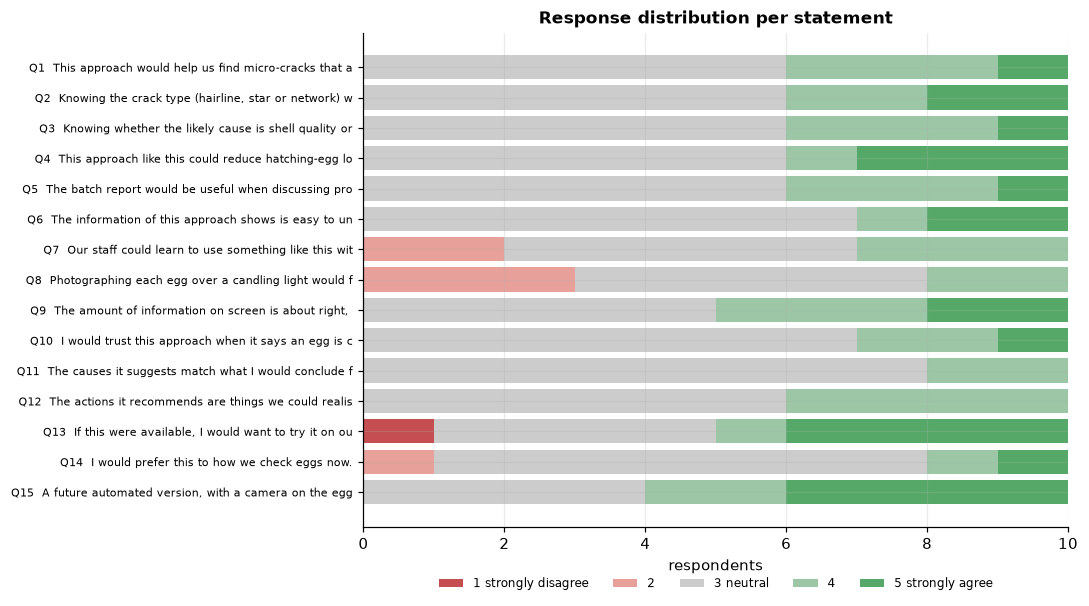

In [9]:
# --- distribution of responses per item, which a mean hides ---------------
dist = pd.DataFrame({q: L[q].value_counts().reindex([1, 2, 3, 4, 5]).fillna(0).astype(int)
                     for q in QS}).T
dist.columns = ["1 strongly disagree", "2", "3 neutral", "4", "5 strongly agree"]
dist.to_csv(TAB_DIR / "t04_response_distribution.csv")
print(dist.to_string())

fig, ax = plt.subplots(figsize=(10, 5.6))
left = np.zeros(len(dist))
shades = ["#C44E52", "#E8A09A", "#CCCCCC", "#9CC6A5", "#55A868"]
for col, sh in zip(dist.columns, shades):
    ax.barh(range(len(dist)), dist[col], left=left, color=sh, label=col)
    left += dist[col].values
ax.set_yticks(range(len(dist)))
ax.set_yticklabels([f"{q}  {items.loc[q, 'statement'][:52]}" for q in dist.index], fontsize=7.5)
ax.invert_yaxis(); ax.set_xlabel("respondents"); ax.legend(fontsize=8, ncol=5,
                                                           loc="upper center",
                                                           bbox_to_anchor=(0.5, -0.08))
ax.set_title("Response distribution per statement")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_distribution.png", bbox_inches="tight")
plt.show()

---
## 4. Open responses

Exported for thematic coding. **Code these by hand** and put the coding frame in the appendix. With
ten practitioners the free text is usually worth more than the ratings: it is where the adoption
barriers and the workflow-fit problems actually appear.

In [10]:
OPEN = [f"O{i}" for i in range(1, 6) if f"O{i}" in colmap]
if OPEN:
    rows = []
    for i, r in df.iterrows():
        for o in OPEN:
            txt = str(r[colmap[o]]).strip()
            if txt and txt.lower() not in ("nan", "-", "none"):
                rows.append({"respondent": f"R{i + 1:02d}", "question": o,
                             "prompt": labels[o], "response": txt, "theme": ""})
    qual = pd.DataFrame(rows)
    qual.to_csv(TAB_DIR / "t05_open_responses.csv", index=False)
    S["n_open_responses"] = int(len(qual))
    for o in OPEN:
        print(f"\n{'=' * 72}\n{o}. {labels[o]}\n{'=' * 72}")
        for _, r in qual[qual["question"].eq(o)].iterrows():
            print(f"  {r['respondent']}: {r['response']}")
    print(f"\n\n{len(qual)} open responses exported to t05_open_responses.csv with an empty")
    print("'theme' column. Fill it in yourself. Suggested starting frame, then revise:")
    print("   current loss causes · where it fits in the process · trust and evidence needed ·")
    print("   labour and time · cost · hardware and automation · training · data and records")


O1. What is the biggest cause of hatching-egg loss on your farm at the moment?
  R01: Egg quality and handling issues
  R02: Hairline cracks occurring during automated collection and transfer belts before they even reach the main setter room.
  R03: Sub-visual micro cracks that slip past manual visual checks
  R04: Hairline cracks occurring during automated collection and transfer belts before they even reach the main setter room.
  R05: Rough handling by collection staff and occasional shell weakness in older breeder flocks.
  R06: Transport vibrations from farm-to-hatchery trucks and improper packing density on trays.
  R07: Thin eggshells from older flocks eexperiencing nutritional imbalances late in their cycle
  R08: Hairline stress fractures caused by fluctuating temperature and humidity during farmsite storage
  R09: hairline stress fractures caused by fluctuating temperature and humidity during farm-site storage.
  R10: Thin eggshells from older flocks experiencing nutritional

In [11]:
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "appraisal_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

Lg = ["=" * 70, "NOTEBOOK 12 DIGEST -- STAKEHOLDER APPRAISAL", "=" * 70,
      f"generated: {S['generated_at']}", f"respondents: {N}", "",
      "METHOD: post-demonstration appraisal using TAM-based items.",
      "Participants did NOT operate the system. This is not a usability study and no",
      "usability, learnability or task-performance claim may be made from it.", "",
      "CONSTRUCTS (1-5)"]
for r in S["constructs"]:
    al = "n/a" if r["cronbach_alpha"] != r["cronbach_alpha"] else f"{r['cronbach_alpha']:.2f}"
    Lg.append(f"   {r['construct']:<26s} {r['mean']:.2f}  "
              f"[{r['ci_low']:.2f}, {r['ci_high']:.2f}]  "
              f"{r['pct_agree']:.0f}% agree  alpha {al}")
Lg += ["", "ITEMS"]
for r in S["items"]:
    Lg.append(f"   {r['item']:<4s} {r['mean']:.2f} +/- {r['sd']:.2f}  "
              f"{r['pct_agree']:>5.1f}% agree   {r['statement'][:54]}")
Lg += ["", f"open responses collected: {S.get('n_open_responses', 0)}",
       "", "=" * 70]
digest = "\n".join(Lg)
(OUT / "digest.txt").write_text(digest)
print(digest)

NOTEBOOK 12 DIGEST -- STAKEHOLDER APPRAISAL
generated: 2026-10-13T20:16:04
respondents: 10

METHOD: post-demonstration appraisal using TAM-based items.
Participants did NOT operate the system. This is not a usability study and no
usability, learnability or task-performance claim may be made from it.

CONSTRUCTS (1-5)
   Perceived usefulness       3.56  [3.03, 4.09]  40% agree  alpha 0.97
   Ease of use and fit        3.30  [2.85, 3.75]  32% agree  alpha 0.81
   Trust and credibility      3.33  [3.02, 3.65]  30% agree  alpha 0.71
   Behavioural intention      3.63  [3.09, 4.18]  43% agree  alpha 0.55

ITEMS
   Q1   3.50 +/- 0.71   40.0% agree   This approach would help us find micro-cracks that are
   Q2   3.60 +/- 0.84   40.0% agree   Knowing the crack type (hairline, star or network) wou
   Q3   3.50 +/- 0.71   40.0% agree   Knowing whether the likely cause is shell quality or h
   Q4   3.70 +/- 0.95   40.0% agree   This approach like this could reduce hatching-egg loss
   Q5   3.50 +